<a href="https://colab.research.google.com/github/bitarahimi525/gene-to-protein-analysis-/blob/main/gene_to_protein_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Gene-to-Protein Sequence Analysis: Human Insulin (INS)

This notebook walks through a basic sequence-analysis workflow in Python:
retrieving a gene record from NCBI, translating its coding sequence into a
protein, and comparing that protein against curated sequences with BLAST.

Why insulin? Insulin is short, extremely well studied, and conserved across
vertebrates, which makes the BLAST output easy to interpret. It is also a
classic biotechnology product: recombinant human insulin was one of the first
therapeutic proteins produced in microbial hosts.

Workflow
1. Retrieve the mRNA record NM_000207 (human INS, transcript variant 1) from NCBI
2. Calculate GC content and translate the coding sequence (CDS)
3. Run BLASTp against the SwissProt database
4. Summarize the top hits in a table and a chart

Tools: Python, Biopython, pandas, matplotlib, NCBI Entrez and BLAST

In [20]:
!pip install biopython pandas matplotlib


## 1. Sequence retrieval and translation

The record was downloaded in GenBank format with Biopython's Entrez.efetch.
A GenBank record contains the full mRNA sequence plus annotations (features).
The CDS feature marks the coding region, so the sequence is extracted from
it and translated until the first stop codon.

In [21]:
from Bio import Entrez, SeqIO
from Bio.SeqUtils import gc_fraction

Entrez.email = "your_email@example.com"
ACCESSION = "NM_000207"

handle = Entrez.efetch(db="nucleotide", id=ACCESSION,
                       rettype="gb", retmode="text")
record = SeqIO.read(handle, "genbank")
handle.close()

print("Record ID:", record.id)
print("Description:", record.description)
print("Length (bp):", len(record.seq))
print("GC content: %.1f%%" % (100 * gc_fraction(record.seq)))

for feature in record.features:
    if feature.type == "CDS":
        cds = feature.extract(record.seq)
        protein = cds.translate(to_stop=True)
        break

print("Protein length (aa):", len(protein))
print("Protein:", protein)

with open("ins_protein.fasta", "w") as f:
    f.write(">INS_human_protein\n" + str(protein) + "\n")

Record ID: NM_000207.3
Description: Homo sapiens insulin (INS), transcript variant 1, mRNA
Length (bp): 465
GC content: 63.9%
Protein length (aa): 110
Protein: MALWMRLLPLLALLALWGPDPAAAFVNQHLCGSHLVEALYLVCGERGFFYTPKTRREAEDLQVGQVELGGGPGAGSLQPLALEGSLQKRGIVEQCCTSICSLYQLENYCN


Output summary
- Record: NM_000207.3 (human INS, transcript variant 1), 465 bp.
- GC content: 63.9%.
- The translated product is 110 amino acids: preproinsulin, the precursor of insulin.
- The mRNA is longer than the coding region because it includes 5' and 3'
  untranslated regions (UTRs), which are not translated.

Organization of preproinsulin (boundaries follow the known domain layout
of human preproinsulin; compare with the UniProt entry P01308)

| Region | Residues | Length | Role |
|---|---|---|---|
| Signal peptide | 1–24 | 24 aa | Directs the protein into the secretory pathway, then is removed |
| B chain | 25–54 | 30 aa | Part of mature insulin |
| C-peptide with cleavage sites | 55–89 | 35 aa | C-peptide (31 aa) flanked by the dibasic sites RR and KR; removed during processing |
| A chain | 90–110 | 21 aa | Part of mature insulin |

Mature insulin consists of the A and B chains linked by disulfide bonds.

## 2. Comparing the protein with BLAST

BLAST (Basic Local Alignment Search Tool) searches a database for sequences
similar to a query. Here, blastp compares the insulin protein with
SwissProt, a manually curated protein database.

Three values are used to read the results:
- Identity (%): the share of aligned positions with the same amino acid.
- E-value: the number of matches expected by chance for a hit of this
  quality. Smaller values mean a stronger match.
- Alignment length: how much of the query the hit covers.

Because the query is human insulin and SwissProt contains human insulin, the
top hit is expected to be the query itself with 100% identity.

In [22]:
from Bio.Blast import NCBIWWW, NCBIXML

print("Running BLAST... this can take 1-5 minutes")
result_handle = NCBIWWW.qblast("blastp", "swissprot",
                               str(protein), hitlist_size=10)
blast_record = NCBIXML.read(result_handle)
result_handle.close()
print("Number of hits:", len(blast_record.alignments))


Running BLAST... this can take 1-5 minutes
Number of hits: 10


In [23]:
import time

def get_organism(accession):
    h = Entrez.efetch(db="protein", id=accession, rettype="gb", retmode="text")
    rec = SeqIO.read(h, "genbank")
    h.close()
    time.sleep(0.4)  # stay within NCBI's request rate limit
    return rec.annotations.get("organism", "unknown")

organisms = [get_organism(a.accession) for a in blast_record.alignments]
print(organisms)

['Homo sapiens', 'Pongo pygmaeus', 'Pan troglodytes', 'Macaca fascicularis', 'Chlorocebus aethiops', 'Rattus norvegicus', 'Cricetulus longicaudatus', 'Aotus trivirgatus', 'Rattus norvegicus', 'Canis lupus familiaris']


In [24]:
import pandas as pd

rows = []
for aln, org in zip(blast_record.alignments, organisms):
    hsp = aln.hsps[0]
    rows.append({
        "accession": aln.accession,
        "organism": org,
        "description": aln.title[:60],
        "identity_%": round(100 * hsp.identities / hsp.align_length, 1),
        "e_value": hsp.expect,
        "alignment_length": hsp.align_length,
    })

df = pd.DataFrame(rows)
df

,accession,organism,description,identity_%,e_value,alignment_length
0,P01308,Homo sapiens,sp|P01308.1| RecName: Full=Insulin; Contains: ...,100.0,1.583820e-76,110
1,Q8HXV2,Pongo pygmaeus,sp|Q8HXV2.1| RecName: Full=Insulin; Contains: ...,99.1,7.529560e-76,110
2,P30410,Pan troglodytes,sp|P30410.1| RecName: Full=Insulin; Contains: ...,98.2,1.130280e-75,110
3,P30406,Macaca fascicularis,sp|P30406.1| RecName: Full=Insulin; Contains: ...,98.2,1.146080e-74,110
4,P30407,Chlorocebus aethiops,sp|P30407.1| RecName: Full=Insulin; Contains: ...,97.3,3.962580e-74,110
5,P01323,Rattus norvegicus,sp|P01323.1| RecName: Full=Insulin-2; Contains...,82.7,3.411990e-56,110
6,P01313,Cricetulus longicaudatus,sp|P01313.2| RecName: Full=Insulin; Contains: ...,82.7,3.604360e-56,110
7,P67972,Aotus trivirgatus,sp|P67972.1| RecName: Full=Insulin; Contains: ...,85.5,9.597170e-56,110
8,P01322,Rattus norvegicus,sp|P01322.1| RecName: Full=Insulin-1; Contains...,82.7,1.067740e-55,110
9,P01321,Canis lupus familiaris,sp|P01321.1| RecName: Full=Insulin; Contains: ...,88.2,3.268740e-55,110


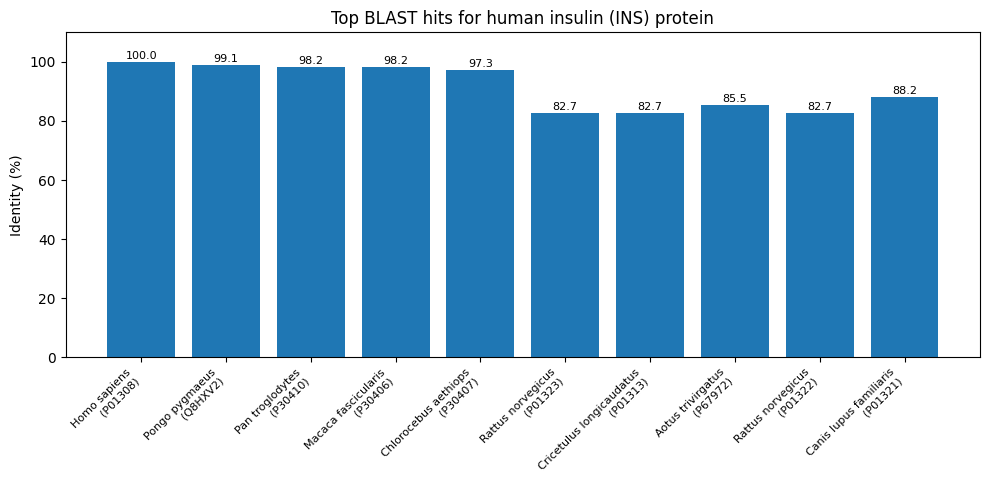

In [25]:
import matplotlib.pyplot as plt

labels = [f"{o}\n({a})" for o, a in zip(df["organism"], df["accession"])]

plt.figure(figsize=(10, 5))
bars = plt.bar(range(len(df)), df["identity_%"])
plt.xticks(range(len(df)), labels, rotation=45, ha="right", fontsize=8)
plt.ylabel("Identity (%)")
plt.title("Top BLAST hits for human insulin (INS) protein")
plt.ylim(0, 110)

for b, v in zip(bars, df["identity_%"]):
    plt.text(b.get_x() + b.get_width() / 2, v + 1, str(v),
             ha="center", fontsize=8)

plt.tight_layout()
plt.savefig("blast_identity.png", dpi=150)
plt.show()
df.to_csv("blast_results.csv", index=False)

## 3. Results

- Best hit: P01308 (*Homo sapiens*), 100% identity over 110 aa
  (E-value 1.6e-76), as expected for a self-match.
- Next four hits (97.3–99.1% identity): all primates: *Pongo pygmaeus*,
  *Pan troglodytes*, *Macaca fascicularis* and *Chlorocebus aethiops*. The
  closest, *Pongo pygmaeus* (99.1%), differs from human insulin at a single position.
- Remaining hits (82.7–88.2% identity): *Rattus norvegicus* (two entries,
  Insulin-1 and Insulin-2, 82.7% each), *Cricetulus longicaudatus* (82.7%),
  *Aotus trivirgatus* (85.5%) and *Canis lupus familiaris* (88.2%).
- Ranking note: BLAST ranks hits by alignment score and E-value, not by
  identity alone, so identity percentages are not strictly decreasing in the table.
- All ten hits align over the full 110 aa with very small E-values
  (1e-76 to 3e-55), so none of them is a chance match.

Interpretation. Insulin is highly conserved among vertebrates, because its
structure is tied to binding the insulin receptor. The ten hits split into two
groups: the five closest are great apes and Old World monkeys, while the second
group contains rodents, a carnivore and a New World monkey with noticeably
lower identity. One result does not follow simple taxonomic closeness: the owl
monkey *Aotus trivirgatus* (a primate, 85.5%) is less similar to human insulin
than the dog (88.2%). This shows that identity for a single protein does not
always mirror species relatedness; the cause was not investigated here.
Identity values describe sequence similarity, not function.

## 4. Limitations and next steps

Limitations
- Only one gene and only the ten top BLAST hits were analyzed.
- Identity describes sequence similarity, not function; it does not by itself prove evolutionary or functional relationships.
- BLAST was run against SwissProt only. A larger database (e.g. nr) could return a different set of hits.
- The analysis uses the preproinsulin precursor, not the mature A and B chains on their own.

Possible extensions
- Run the same workflow for another gene and compare the results
- Build a multiple sequence alignment of the top hits
- Compare the mature A and B chains separately from the full precursor